# 下次优先办什么？
先预测，再运行，再解释。数据为合成练习数据。每行是一条报名，不是唯一学生。

## 0 准备
在解压后的“学生练习”文件夹打开本笔记本。若使用 notebook，请选择装有 pandas、matplotlib 的 Python 内核。

In [6]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path.cwd()
print(BASE)
assert (BASE / "activities.csv").exists(), "请把工作目录设为学生练习"
OUT = BASE / "outputs"
OUT.mkdir(exist_ok=True)
raw = pd.read_csv(BASE / "activities.csv")
raw.head()

/content


,registration_id,activity,session,year,attended,rating
0,R0383,Film,Film-3,3,0,NaN
1,R0766,Hiking,Hiking-1,2,1,4.0
2,R0440,BoardGames,BoardGames-5,4,1,5.0
3,R0969,Craft,Craft-4,3,1,4.0
4,R0876,Hiking,Hiking-1,4,1,NaN


## 先做小表练习
pd是pandas别名，DataFrame是表格，选择一列得到Series。每个操作都先预测，再运行。


In [7]:
toy = pd.DataFrame({
    "activity": ["Film", "Film", "BoardGames", "BoardGames"],
    "attended": [1, 0, 1, 1],
    "rating": [5, None, 3, None]
})
print(toy)
# 依照讲义新工具1–3页，逐步完成选择列、isna和筛选练习。


     activity  attended  rating
0        Film         1     5.0
1        Film         0     NaN
2  BoardGames         1     3.0
3  BoardGames         1     NaN


## A 认识数据
打印数据行数、列名；检查 attended 和 rating 的取值。解释一行代表什么。

In [8]:
# 在这里完成
print(len(raw))
print(raw.columns)
print(raw[["activity","attended"]].head(10))
hiking = raw[raw['activity'] == 'Hiking']
print(len(hiking))
print(raw["attended"].sum())
print(raw["attended"].mean())
print(raw["attended"].median())

1220
Index(['registration_id', 'activity', 'session', 'year', 'attended', 'rating'], dtype='object')
     activity  attended
0        Film         0
1      Hiking         1
2  BoardGames         1
3       Craft         1
4      Hiking         1
5        Film         1
6  BoardGames         1
7      Hiking         1
8      Hiking         0
9      Hiking         0
255
824
0.6754098360655738
1.0


## B 清洗
检查重复 registration_id；按编号去重得到 df。查看缺失评分数。不要删除所有含空值的行。

In [9]:
# 在这里完成
duplicate_mask = raw.duplicated("registration_id")
df = raw.drop_duplicates(subset="registration_id").copy()
print(len(raw),duplicate_mask.sum(),len(df))
print(len(raw) - duplicate_mask.sum() == len(df))


1220 20 1200
True


## C 筛选和统计
计算实际到场总数、总到场率，再算一年级的到场报名数。

In [10]:
# 在这里完成


## D 分组
按活动计算报名数、到场数、到场率、平均评分、评分人数。提示：size / sum / mean / count。

In [11]:
# 在这里完成
groups = toy.groupby("activity")
small_summary = pd.DataFrame({
    "signups": groups.size(),
    "attendance": groups["attended"].sum()
})
small_summary["rate"] = (
    small_summary["attendance"] / small_summary["signups"]
)
small_summary["rating"] = groups["rating"].mean()
print(small_summary)

            signups  attendance  rate  rating
activity                                     
BoardGames        2           2   1.0     3.0
Film              2           1   0.5     5.0


In [20]:
raw = pd.read_csv("activities.csv")
duplicate_count = raw.duplicated("registration_id").sum()
df = raw.drop_duplicates(subset = "registration_id").copy()
print(len(raw),duplicate_count,len(df))

group = df.groupby("activity")
summary = pd.DataFrame({
    "signups": group.size(),
    "attendance": group["attended"].sum()
})
summary["attendance_rate"] = (
    summary["attendance"] / summary["signups"]
)

summary["absent"] = (
    summary["signups"] - summary["attendance"]
)

summary["absence_rate"] = (
    summary["absent"] / summary["signups"]
)
summary = summary.sort_values(
    "absence_rate",ascending = False
)
print(summary)



1220 20 1200
            signups  attendance  attendance_rate  absent  absence_rate
activity                                                              
Film            400         180             0.45     220          0.55
Craft           200         140             0.70      60          0.30
BoardGames      300         240             0.80      60          0.20
Hiking          250         200             0.80      50          0.20
Photo            50          45             0.90       5          0.10


## E 第一张图
按到场数降序画柱状图；标清坐标轴，保存 PNG。

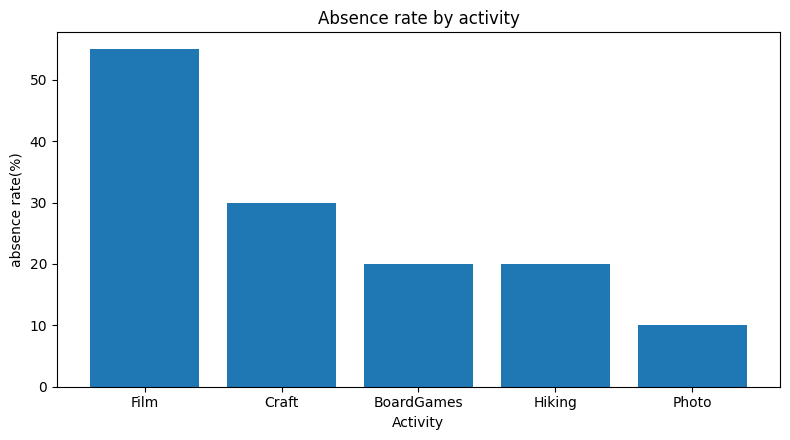

In [21]:
# 在这里完成
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(summary.index, summary["absence_rate"]*100)
ax.set_title("Absence rate by activity")
ax.set_xlabel("Activity")
ax.set_ylabel("absence rate(%)")
ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(OUT / "attendance.png", dpi=300)

## F 独立决策
再画到场率图，导出 summary.csv；选两个优先活动，写 recommendation.md（150–250字，至少3个数字、1个局限、1条后续行动）。

In [13]:
# 在这里完成


## 加分挑战
Photo评分很高，是否应该扩大规模？算评分响应率，结合报名样本量与每场人数，提出还需要什么证据。

In [14]:
# 在这里完成
